In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "masbudget").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path[:0] = [str(ROOT), str(ROOT / "experiments")]
import pandas as pd
from IPython.display import Image, display
from lib import load, md_table
import plots
plots.style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
%matplotlib inline

# E1 - Benchmark profile (LiveCodeBench via LLMRouterBench)

What the allocation problem looks like before any policy runs: the model pool, the per-task outcome structure, the calibrated expected qualities and the shadow price of budget. Produced by `experiments/e01_data_profile.py`; notes in `experiments/E01_data_profile.md`.

## Model pool
Gemini-2.5-Flash and DeepSeek-V3-0324 are dominated on average (more expensive than V3.1, not better). R1 costs 25.7x the cheapest model for +13 points of pass@1.

In [2]:
models = load('e01_models'); models

,model,cost_usd,cost_x_cheapest,pass@1_all,pass@1_easy,pass@1_medium,pass@1_hard,dominated
0,deepseek-v3.1-terminus,0.0011,1.0000,0.6730,1.0,0.9034,0.1165,False
1,deepseek-v3-0324,0.0014,1.2864,0.6664,1.0,0.8665,0.1335,True
2,gemini-2.5-flash,0.0058,5.1863,0.6000,1.0,0.7386,0.0625,True
3,deepseek-r1-0528,0.0289,25.6657,0.8009,1.0,0.9688,0.4347,False


## Which models solve which tasks
Pattern = solved by (V3.1, V3, Flash, R1). Easy tasks are solved by everyone; 178 hard tasks by no one. In the **oracle** regime an agent therefore knows in advance whether a call will pass.

In [3]:
load('e01_patterns')

,difficulty,"solved_by(V3.1,V3,Flash,R1)",tasks
0,easy,1111,351
1,hard,0,178
2,hard,1,70
3,hard,101,32
4,hard,1001,32
5,hard,11,19
6,hard,100,9
7,hard,1100,5
8,hard,1000,4
9,hard,10,2


## Calibrated expected quality (difficulty regime)
Pass rates on the 317-task calibration split, per difficulty label. These are what agents and controllers see as q in the realistic regime.

In [4]:
import lib
qt = lib.quality_tables()
q = pd.DataFrame(qt['difficulty']).T.rename(columns=lib.SHORT)
q.loc['blind'] = pd.Series(qt['blind']).rename(lib.SHORT)
q

,V3.1,V3,Flash,R1
easy,1.0000,1.0000,1.0000,1.0000
medium,0.8868,0.9151,0.7547,0.9623
hard,0.1038,0.0943,0.0849,0.4245
blind,0.6625,0.6688,0.6120,0.7950


### Upgrade value per dollar (the quantities that decide every allocation)

In [5]:
c = lib.MEASURED_COSTS
rows = []
for lv, row in qt['difficulty'].items():
    for m in ('deepseek-v3-0324', 'deepseek-r1-0528'):
        dq = row[m] - row['deepseek-v3.1-terminus']; dc = c[m] - c['deepseek-v3.1-terminus']
        rows.append({'difficulty': lv, 'upgrade': 'V3.1 -> ' + lib.SHORT[m], 'dq': dq, 'dc_usd': dc, 'dq_per_usd': dq / dc})
pd.DataFrame(rows)

,difficulty,upgrade,dq,dc_usd,dq_per_usd
0,easy,V3.1 -> V3,0.0000,0.0003,0.0000
1,easy,V3.1 -> R1,0.0000,0.0277,0.0000
2,medium,V3.1 -> V3,0.0283,0.0003,87.8495
3,medium,V3.1 -> R1,0.0755,0.0277,2.7200
4,hard,V3.1 -> V3,-0.0094,0.0003,-29.2832
5,hard,V3.1 -> R1,0.3208,0.0277,11.5598


## Shadow price of budget lambda*(tau)
The Lagrangian price of the MCKP relaxation. In the difficulty regime it is a *step function*: flat at 11.56 pass@1/$ (= the ROI of V3.1 -> R1 on hard tasks) for tau in [0.02, 0.33]. At that price every hard task is indifferent, so a static posted price cannot implement the optimum - a price that moves with spending can.

In [6]:
pc = load('e01_price_curve'); pc[pc.pricing == 'measured'].pivot(index='tau', columns='regime', values='lambda_star')

regime,blind,difficulty,oracle
tau,,,
0.00,19.5837,87.8495,3104.0156
0.02,4.6010,11.5598,36.0395
0.05,4.6010,11.5598,36.0395
0.10,4.6010,11.5598,0.0000
0.15,4.6010,11.5598,0.0000
0.20,4.6010,11.5598,0.0000
0.25,4.6010,11.5598,0.0000
0.30,4.6010,11.5598,0.0000
0.35,4.6010,1.7199,0.0000


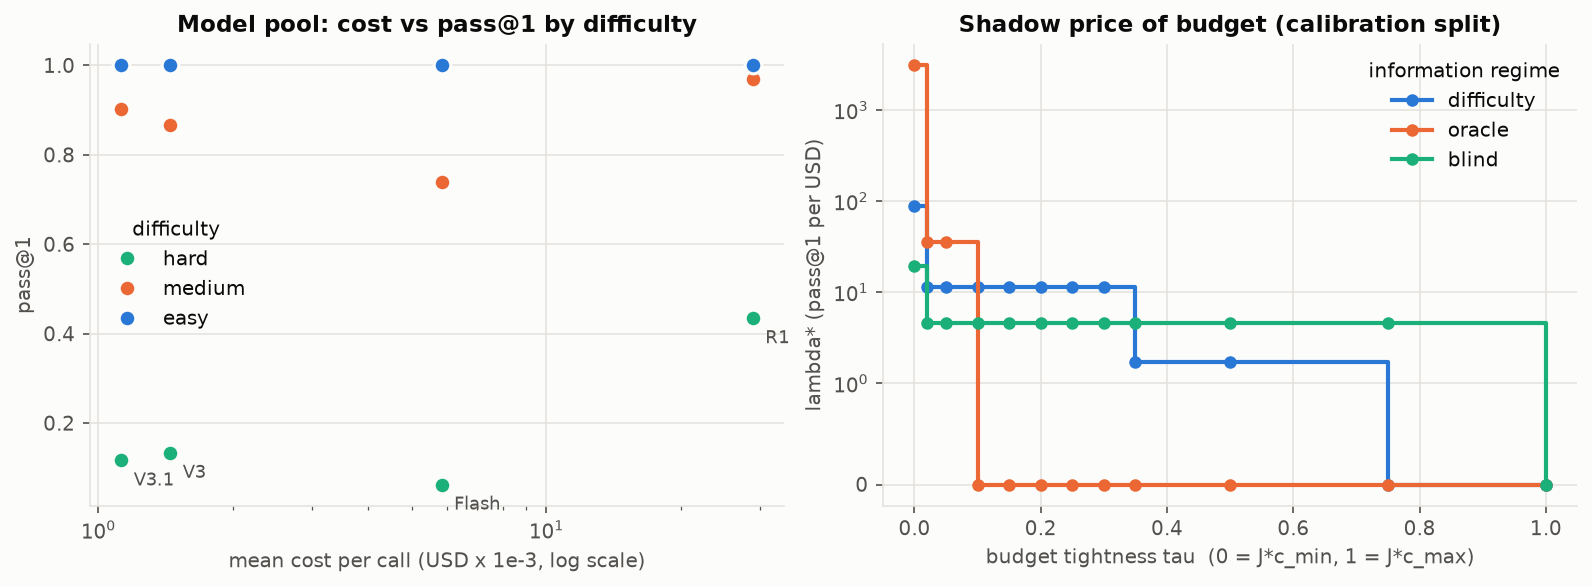

In [7]:
display(Image('experiments/figures/e01_profile.png'))